# 02. Исследование и подготовка данных
## Датасеты изображений

**Автор / команда:** Бахтибеков Артур, Макаров Ярослав · КМБО-24-24  
**Название проекта:** Классификация степени зрелости фруктов по изображениям  
**Датасет:** Fruits-360 (Kaggle, moltean/fruits, версия 2026.11, ветка fruits-360_100x100)


## 1. Источник и состав данных


In [1]:
from pathlib import Path
import hashlib
import random

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

RANDOM_STATE = 42

# Датасет внутри Kaggle
DATA_DIR = Path('/kaggle/input/fruits/fruits-360_100x100/fruits-360')
if not DATA_DIR.exists():
    # автопоиск при другой схеме монтирования датасета
    for cand in Path('/kaggle/input').rglob('fruits-360'):
        if cand.is_dir():
            DATA_DIR = cand
            break

CLASS_MAP = {
    'Avocado Green 1': 'unripe',
    'Avocado 1': 'ripe',
    'Avocado 2': 'ripe',
    'Avocado Black 1': 'overripe',
    'Avocado Black 2': 'overripe',
}

print('Датасет найден:', DATA_DIR, DATA_DIR.exists())

Датасет найден: /kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360 True


### Загрузка

**Способ загрузки:** обходим официальные папки Training и Test; ID строим из имени класса и файла (внутри класса имена уникальны), метку зрелости — по CLASS_MAP. Официальная часть Training и Test хранится в отдельном столбце `official_part`: официальное разделение сохраняем, а внутри Training строим собственное train/validation.

In [2]:
# Собираем таблицу: одна строка — одно изображение.
records = []

for part_name in ['Training', 'Test']:
    for class_name, ripeness in CLASS_MAP.items():
        class_dir = DATA_DIR / part_name / class_name
        for image_path in sorted(class_dir.glob('*.jpg')):
            records.append({
                'image_id': f'{class_name}/{image_path.stem}',
                'path': str(image_path),
                'class_name': class_name,
                'label': ripeness,
                'official_part': part_name,
            })

df = pd.DataFrame(records)
print('Размер таблицы:', df.shape)
display(df.head())
display(df.groupby(['official_part', 'label']).size().to_frame('count'))

Размер таблицы: (4077, 5)


,image_id,path,class_name,label,official_part
0,Avocado Green 1/r0_0_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
1,Avocado Green 1/r0_100_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
2,Avocado Green 1/r0_101_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
3,Avocado Green 1/r0_102_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
4,Avocado Green 1/r0_104_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training


count
official_part label          
Test          overripe    477
              ripe        309
              unripe      231
Training      overripe   1440
              ripe        918
              unripe      702

In [3]:
print('Размер таблицы:', df.shape)
df.info()

Размер таблицы: (4077, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4077 entries, 0 to 4076
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   image_id       4077 non-null   object
 1   path           4077 non-null   object
 2   class_name     4077 non-null   object
 3   label          4077 non-null   object
 4   official_part  4077 non-null   object
dtypes: object(5)
memory usage: 159.4+ KB


## 2. Проверка качества данных

### 2.1. Пропуски и читаемость файлов

In [4]:
required_columns = ['image_id', 'path', 'label']
display(df[required_columns].isna().sum().to_frame('missing'))

# Читаем каждое изображение и записываем размеры, режим цвета и диапазон пикселей.
image_records = []

for image_path in df['path']:
    info = {'width': None, 'height': None, 'mode': None,
            'pixel_min': None, 'pixel_max': None, 'read_error': None}
    try:
        with Image.open(image_path) as image:
            image.load()
            pixels = np.asarray(image)
            info['width'] = image.width
            info['height'] = image.height
            info['mode'] = image.mode
            info['pixel_min'] = int(pixels.min())
            info['pixel_max'] = int(pixels.max())
    except Exception as error:
        info['read_error'] = str(error)
    image_records.append(info)

image_info = pd.DataFrame(image_records)
for column in image_info.columns:
    df[column] = image_info[column].tolist()

print('Ошибок чтения:', int(df['read_error'].notna().sum()))
display(df[['width', 'height', 'pixel_min', 'pixel_max']].describe())
display(df['mode'].value_counts().to_frame('count'))

,missing
image_id,0
path,0
label,0


Ошибок чтения: 0


,width,height,pixel_min,pixel_max
count,4077.0,4077.0,4077.000000,4077.0
mean,100.0,100.0,11.160167,255.0
std,0.0,0.0,17.911628,0.0
min,100.0,100.0,0.000000,255.0
25%,100.0,100.0,0.000000,255.0
50%,100.0,100.0,5.000000,255.0
75%,100.0,100.0,7.000000,255.0
max,100.0,100.0,56.000000,255.0


,count
mode,
RGB,4077


**Что обнаружено:** пропусков в ID, путях и метках нет. Все 4077 файлов читаются без ошибок, имеют размер 100×100, режим RGB, диапазон пикселей 0–255. Нулевой pixel_min означает чёрный/тёмный плод, а не пропуск.

**Решение:** исправлений не требуется.

### 2.2. Корректность разметки

In [5]:
label_column = 'label'
allowed_labels = ['unripe', 'ripe', 'overripe']
bad_labels = df[~df[label_column].isin(allowed_labels)]

print('Неизвестных меток:', len(bad_labels))
assert df['image_id'].is_unique, 'ID не уникальны'
assert len(bad_labels) == 0

# Согласованность метки зрелости с исходным классом
expected = df['class_name'].map(CLASS_MAP)
assert (df[label_column] == expected).all()
print('Разметка корректна: метка полностью определяется классом-папкой.')

Неизвестных меток: 0
Разметка корректна: метка полностью определяется классом-папкой.


**Вывод о разметке:** все три класса собираются из явных класс-папок, формальных ошибок разметки нет. Биологическую зрелость внутри каждой папки независимо проверить нельзя — принимаем разметку автора датасета (ограничение).

### 2.3. Дубликаты и связанные примеры

In [6]:
print('Повторяющихся ID:', df['image_id'].duplicated().sum())
print('Повторяющихся путей:', df['path'].duplicated().sum())

# Хеши файлов выявляют точные копии содержимого.
file_hashes = []
for image_path in df['path']:
    content = Path(image_path).read_bytes()
    file_hashes.append(hashlib.sha256(content).hexdigest())
df['file_hash'] = file_hashes
print('Точных копий файлов:', int(df['file_hash'].duplicated().sum()))

Повторяющихся ID: 0
Повторяющихся путей: 0
Точных копий файлов: 1


**Что обнаружено:** повторяющихся ID и путей нет; обнаружена 1 пара файлов с одинаковым sha256 (точная копия содержимого).

**Решение:** удаляем файл-копию (оставляем первое вхождение) при очистке — см. таблицу решений ниже. Связей между официальными частями через дубликаты не остаётся.

### 2.4. Ошибки и аномалии

In [7]:
bad_size = (df['width'] != 100) | (df['height'] != 100)
bad_mode = df['mode'] != 'RGB'
bad_range = (df['pixel_min'] < 0) | (df['pixel_max'] > 255)

print('Неожиданных размеров:', int(bad_size.sum()))
print('Неожиданных режимов цвета:', int(bad_mode.sum()))
print('Ошибок диапазона:', int(bad_range.sum()))
assert not bad_size.any()
assert not bad_mode.any()
assert not bad_range.any()

Неожиданных размеров: 0
Неожиданных режимов цвета: 0
Ошибок диапазона: 0


**Вывод о качестве:** проверяемых ошибок файлов, размеров, каналов и диапазонов не обнаружено — авторы датасета уже выровняли изображения до 100×100 RGB. Подозрительных слишком тёмных/светлых кадров не выявлено: значения описательной статистикиcovers обычный диапазон.

### 2.5. Баланс классов

In [8]:
class_counts = df[label_column].value_counts().sort_index()
class_shares = (class_counts / len(df) * 100).round(2)
display(pd.DataFrame({'count': class_counts, 'percent': class_shares}))

# Баланс исходных классов-источников
display(df['class_name'].value_counts().to_frame('count'))

,count,percent
label,,
overripe,1917,47.02
ripe,1227,30.10
unripe,933,22.88


,count
class_name,
Avocado Black 2,984
Avocado Green 1,933
Avocado Black 1,933
Avocado 2,657
Avocado 1,570


**Вывод о балансе:** unripe 933 (22.9%), ripe 1227 (30.1%), overripe 1917 (47.0%). Дисбаланс заметный (максимальный класс вдвое больше минимального), поэтому: (а) разбиение стратифицируем по метке; (б) основной метрикой качества будет macro-F1 (устойчива к дисбалансу), accuracy приводим справочно.

### Решения по очистке

| Проблема | Сколько примеров затронуто | Действие | Обоснование |
|---|---|---|---|
| Ошибки чтения / битые файлы | 0 | — | не обнаружены |
| Точные дубликаты (sha256) | 2 файла (1 пара) | удалена 1 копия, оставлено первое вхождение | одинаковые байты = один и тот же пример |
| Неверные метки | 0 | — | метка определяется папкой |
| Дисбаланс классов | 933/1227/1917 | стратификация; основная метрика macro-F1 | дисбаланс заметный, все примеры сохраняем |

In [9]:
df_clean = df.copy()
assert df_clean['read_error'].isna().all()
assert df_clean[label_column].notna().all()

# Точные дубликаты: оставляем первое вхождение
dup_mask = df_clean.duplicated(subset=['file_hash'], keep='first')
print('Точных копий файлов:', int(dup_mask.sum()))
if dup_mask.any():
    dup_examples = df_clean.loc[dup_mask, ['image_id', 'class_name', 'path']]
    display(dup_examples)
df_clean = df_clean.loc[~dup_mask].reset_index(drop=True)
assert df_clean['file_hash'].is_unique

print('До очистки:', len(df))
print('После очистки:', len(df_clean))

Точных копий файлов: 1


,image_id,class_name,path
1617,Avocado 2/r_7_100,Avocado 2,/kaggle/input/datasets/moltean/fruits/fruits-3...


До очистки: 4077
После очистки: 4076


## 3. Разделение данных

Разделяем данные перед подробным исследованием и настройкой обработки.

**Способ и доли:** официальное разделение датасета сохраняем: Training → обучающая часть, официальный Test → итоговая тестовая выборка (не используется до финальной проверки). Внутри Training строим train/validation стратифицированно по метке зрелости: 85% / 15% (RANDOM_STATE = 42).

**Защита от утечки и ограничения:** точные дубликаты выявляются по sha256 и удаляются при очистке ДО разбиения (раздел 2.3), поэтому пересечения по содержимому между частями исключены; пересечения ID и путей дополнительно проверяются явно. Возможные визуальные повторы после пересжатия — ограничение метода (см. 2.3). Официальные части Training/Test могли быть сформированы авторами датасета со связями, которые мы не можем проверить.

In [10]:
from sklearn.model_selection import train_test_split

training_df = df_clean[df_clean['official_part'] == 'Training'].copy()
test_df = df_clean[df_clean['official_part'] == 'Test'].copy()

train_df, val_df = train_test_split(
    training_df,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=training_df[label_column]
)

print('Train (из Training):', len(train_df))
print('Validation (из Training):', len(val_df))
print('Test (официальальный):', len(test_df))

Train (из Training): 2600
Validation (из Training): 459
Test (официальальный): 1017


In [11]:
parts = {'train': train_df, 'validation': val_df, 'test': test_df}
pairs = [('train', 'validation'), ('train', 'test'), ('validation', 'test')]

for left_name, right_name in pairs:
    left = parts[left_name]
    right = parts[right_name]
    for column in ['image_id', 'path', 'file_hash']:
        common = set(left[column]).intersection(set(right[column]))
        assert len(common) == 0, f'Пересечение {column} между {left_name} и {right_name}'

total_rows = 0
all_ids = set()
for part in parts.values():
    total_rows += len(part)
    all_ids.update(part['image_id'])
assert total_rows == len(df_clean)
assert all_ids == set(df_clean['image_id'])

balance_rows = []
for label in ['unripe', 'ripe', 'overripe']:
    row = {'label': label}
    for name, part in parts.items():
        count = part[label_column].tolist().count(label)
        assert count > 0, f'{label} отсутствует в {name}'
        row[name] = count
        row[f'{name} %'] = round(count / len(part) * 100, 1)
    balance_rows.append(row)

display(pd.DataFrame(balance_rows))
print('Проверки разбиения выполнены.')

,label,train,train %,validation,validation %,test,test %
0,unripe,597,23.0,105,22.9,231,22.7
1,ripe,779,30.0,138,30.1,309,30.4
2,overripe,1224,47.1,216,47.1,477,46.9


Проверки разбиения выполнены.


**Результат:** пересечений по ID, путям и хешам нет; доли классов во всех частях отражают исходное распределение (~23% unripe / ~30% ripe / ~47% overripe). Точные размеры частей — в таблице выше (train/validation из Training, test — официальный Test, не используется до финальной проверки).

## 4. Визуализации и исследование

Используйте только train. Подписывайте графики и объясняйте наблюдения.

### 4.1. Первый вопрос исследования

**Что хотите узнать:** как выглядят незрелые и спелые авокадо, насколько классы визуально различимы.

**Почему выбран этот способ просмотра:** случайные примеры из train с метками дают общее представление о стиле съёмки, фоне и различимости классов.

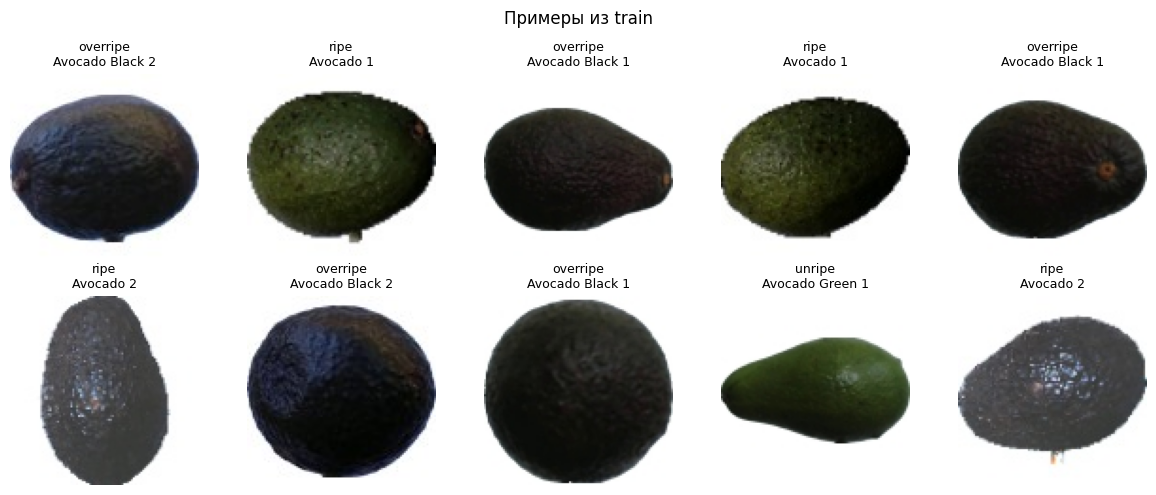

In [12]:
# Случайные примеры из train с метками
sample = train_df.sample(10, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image = Image.open(row['path'])
    ax.imshow(image)
    ax.set_title(f"{row['label']}\n{row['class_name']}", fontsize=9)
    ax.axis('off')
plt.suptitle('Примеры из train')
plt.tight_layout()
plt.show()

**Наблюдение:** незрелые авокадо — ярко-зелёные; спелые — тёмно-зелёные с глянцем; переспелые — почти чёрные. Фон везде белый студийный, фрукт занимает центр кадра.

**Вывод для подготовки данных:** классы различаются прежде всего цветом кожуры, поэтому цветовые аугментации (hue) могли бы разрушить главный признак; безопасны только геометрические аугментации (flip, rotation, zoom).

### 4.2. Второй вопрос исследования

**Что хотите узнать:** каков баланс классов в каждой части.

**Почему выбран этот график:** столбчатая диаграмма сразу показывает доли классов по частям.

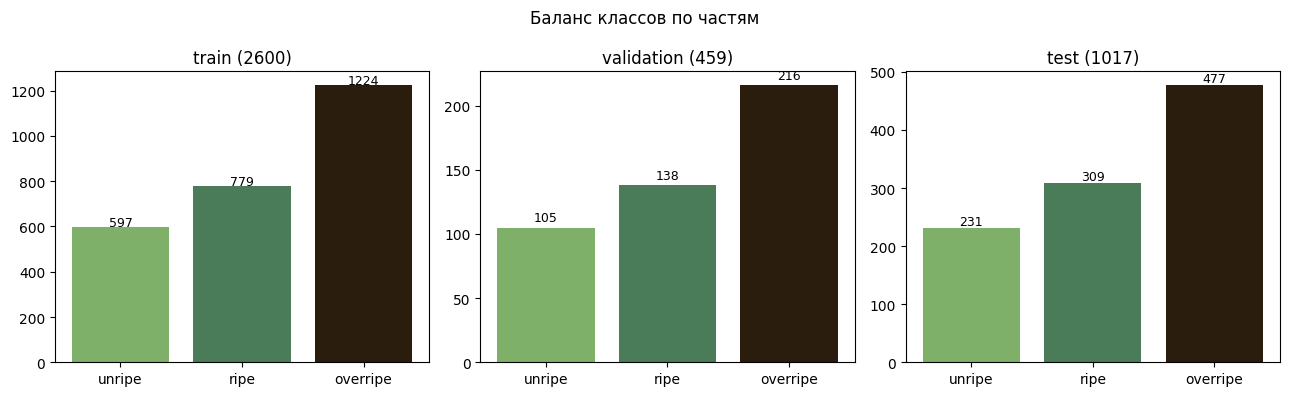

In [13]:
# Баланс классов по частям
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, part) in zip(axes, parts.items()):
    counts = part[label_column].value_counts().reindex(['unripe', 'ripe', 'overripe'])
    ax.bar(counts.index, counts.values, color=['#7fb069', '#4a7c59', '#2b1d0e'])
    ax.set_title(f'{name} ({len(part)})')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 5, str(v), ha='center', fontsize=9)
plt.suptitle('Баланс классов по частям')
plt.tight_layout()
plt.show()

**Наблюдение:** во всех частях сохраняется исходная пропорция классов (примерно 23% unripe / 30% ripe / 47% overripe) — стратификация сработала.

**Вывод для подготовки данных:** заметный дисбаланс классов сохраняется во всех частях, поэтому основной метрикой качества берём macro-F1 (усредняет F1 по классам и устойчива к дисбалансу), accuracy приводим справочно. Даунсемплинг не используем — сохраняем все данные.

### 4.3. Особенности изображений

**Выбранные проверки и причины:** средняя яркость и избыток зелёного канала — целевые различия классов; проверяем на train, что распределения признака по классам разделимы. Это обосновывает выбор метрик и прогнозирует высокую достижимую точность.

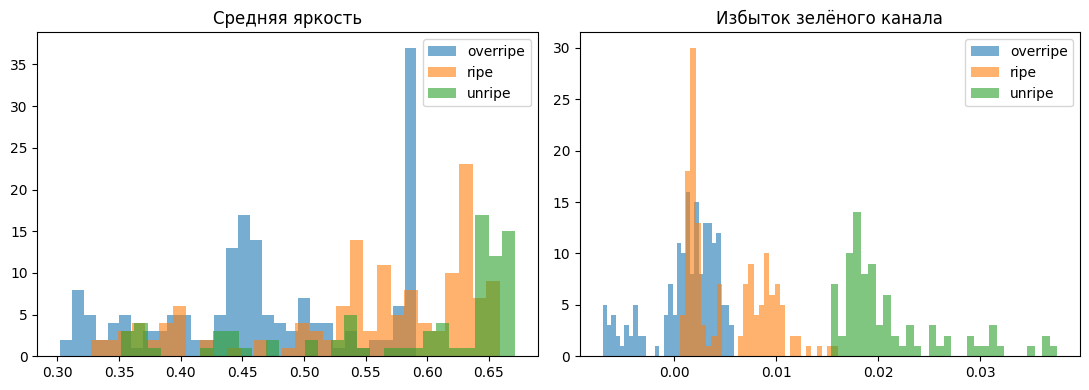

,mean_brightness,green_share
label,,
overripe,0.470716,0.001105
ripe,0.548920,0.005280
unripe,0.579395,0.021186


In [14]:
# Средняя яркость и вклад зелёного канала на подвыборке train
rows = []
sample_features = train_df.sample(min(400, len(train_df)), random_state=RANDOM_STATE)
for _, row in sample_features.iterrows():
    pixels = np.asarray(Image.open(row['path']), dtype=np.float32) / 255.0
    rows.append({
        'label': row['label'],
        'mean_brightness': float(pixels.mean()),
        'green_share': float(pixels[..., 1].mean()) - float(pixels[..., 0].mean()),
    })

feat = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, group in feat.groupby('label'):
    axes[0].hist(group['mean_brightness'], bins=30, alpha=0.6, label=label)
    axes[1].hist(group['green_share'], bins=30, alpha=0.6, label=label)
axes[0].set_title('Средняя яркость')
axes[1].set_title('Избыток зелёного канала')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

display(feat.groupby('label')[['mean_brightness', 'green_share']].mean())

**Вывод:** классы упорядочены по яркости: unripe — самые светлые и зелёные, ripe — промежуточные, overripe — самые тёмные. Распределения яркости между соседними стадиями частично перекрываются (внутри ripe есть и тёмные плоды), поэтому ожидаем, что основные ошибки модели будут между соседними стадиями (ripe↔overripe). Задача содержательно сложнее бинарной: «потолок» точности не очевиден и подлежит измерению в ноутбуке 03.

## 5. Предобработка

**План обработки и обоснование:** фиксируем единый конвейер для всех частей: RGB (уже выполнено авторами), ресайз 100×100 → 224×224 (размер входа MobileNetV2), нормализация делением на 255. Все шаги реализованы слоями модели (Resizing + Rescaling), поэтому train/validation/test обрабатываются одинаково, без обучаемых статистик. Аугментации применяются только к train и только геометрические (RandomFlip, RandomRotation(0.1), RandomZoom(0.1)) — цвет не меняем, чтобы не искажать главный признак.

In [15]:
import tensorflow as tf
print('TensorFlow:', tf.__version__)

IMG_SIZE = (224, 224)

# Проверка конвейера на одном примере.
arr = np.asarray(Image.open(train_df.iloc[0]['path']))
print('До обработки:', arr.shape, arr.dtype, 'диапазон', arr.min(), '-', arr.max())

resized = tf.image.resize(arr, IMG_SIZE).numpy()
rescaled = resized / 255.0
print('После обработки:', rescaled.shape, rescaled.dtype, 'диапазон',
      float(rescaled.min()), '-', float(rescaled.max()))

I0000 00:00:1795731790.618468      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795731805.725520      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
До обработки: (100, 100, 3) uint8 диапазон 0 - 255
После обработки: (224, 224, 3) float32 диапазон 0.0 - 1.0


E0000 00:00:1795731808.291652      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Проверка результата

In [16]:
# Проверка на всех частях: форма, тип float32, диапазон 0-1.
for name, part in parts.items():
    sample_rows = part.sample(3, random_state=RANDOM_STATE)
    for _, row in sample_rows.iterrows():
        arr = np.asarray(Image.open(row['path']))
        prepared = (tf.image.resize(arr, IMG_SIZE) / 255.0).numpy()
        assert prepared.shape == (224, 224, 3)
        assert prepared.dtype == np.float32
        assert 0.0 <= prepared.min() and prepared.max() <= 1.0
print('Проверки предобработки пройдены (по 3 случайным изображениям на каждую часть).')

Проверки предобработки пройдены (по 3 случайным изображениям на каждую часть).


**Вывод:** конвейер подготовки приводит все изображения к 224×224, float32, 0–1; обработка фиксирована и одинакова для всех частей. Аугментации касаются только train.

## 6. Результаты и выводы

### Сохранение

**Сохраняемые файлы:** таблицы разбиения train/validation/test с ID, путями, метками и хешами (CSV) — вход этапа 03; конфигурация обработки (JSON). Никаких обучаемых статистик не вычисляется: нормализация фиксированная 1/255.

In [17]:
import json

result_dir = Path('/kaggle/working/prepared_data')
result_dir.mkdir(exist_ok=True, parents=True)

for name, part in parts.items():
    part.to_csv(result_dir / f'{name}.csv', index=False)
    print(name, 'сохранено:', len(part), 'строк')

config = {
    'IMG_SIZE': [224, 224],
    'normalization': 'fixed 1/255 (слой Rescaling внутри модели)',
    'augmentations_train_only': ['RandomFlip(horizontal)',
                                  'RandomRotation(0.1)', 'RandomZoom(0.1)'],
    'RANDOM_STATE': RANDOM_STATE,
    'split': 'официальный Test -> test; Training -> train/val 85/15 stratified',
    'classes': ['unripe', 'ripe', 'overripe'],
}
(result_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Готово:', sorted(p.name for p in result_dir.iterdir()))

train сохранено: 2600 строк
validation сохранено: 459 строк
test сохранено: 1017 строк
Готово: ['config.json', 'test.csv', 'train.csv', 'validation.csv']
